In [1]:
import os
import pandas as pd
import numpy as np
from tirex2 import TimeseriesType, load_model
import matplotlib.pyplot as plt, torch
from tirex2.plotting import plot_multivariate
import random
import seaborn as sns

def set_seed(seed):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(33)

In [2]:
print("CUDA available:", torch.cuda.is_available())
device = "cuda" if torch.cuda.is_available() else "cpu"

model = load_model("NX-AI/TiRex-2", device=device)

CUDA available: True


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

In [3]:
#test if tirex 2 works
y = torch.sin(torch.arange(160).float() / 8) 
ts = TimeseriesType(target=y[:128].unsqueeze(0), past_covariates=None, future_covariates=None)
forecast = model.forecast([ts], prediction_length=32, output_type="numpy")[0][0]

In [4]:
hourly = pd.read_csv("capital_hourly.csv")
hourly.columns

Index(['timestamp', 'rides_started', 'member_rides', 'casual_rides',
       'classic_rides', 'docked_rides', 'electric_rides', 'unknown_rides',
       'avg_duration_min', 'avg_distance_km', 'date', 'hour', 'dow', 'month',
       'is_weekend', 'is_holiday', 'temp', 'precip', 'snowfall', 'humidity',
       'windspeed', 'windgust', 'cloudcover', 'is_rain', 'is_heavy_rain',
       'is_snow', 'weather_regime'],
      dtype='str')

In [5]:
#daily = pd.read_csv("capital_station_daily.csv")
#daily
#not used

In [6]:
hourly["timestamp"] = pd.to_datetime(hourly["timestamp"])
dt = pd.DatetimeIndex(hourly["timestamp"])

hourly["bin_of_day"] = dt.hour # 0 to 23 
hourly["dow"] = dt.dayofweek # 0 to 6
hourly["month"] = dt.month # 1 to 12

In [7]:
hourly

,timestamp,rides_started,member_rides,casual_rides,classic_rides,docked_rides,electric_rides,unknown_rides,avg_duration_min,avg_distance_km,...,snowfall,humidity,windspeed,windgust,cloudcover,is_rain,is_heavy_rain,is_snow,weather_regime,bin_of_day
0,2020-01-01 00:00:00,106,86,20,0,0,0,106,15.609748,NaN,...,0.0,54,17.8,37.4,94,0,0,0,dry,0
1,2020-01-01 01:00:00,120,114,6,0,0,0,120,16.791250,NaN,...,0.0,54,18.5,36.0,81,0,0,0,dry,1
2,2020-01-01 02:00:00,102,86,16,0,0,0,102,13.258660,NaN,...,0.0,53,19.7,38.5,85,0,0,0,dry,2
3,2020-01-01 03:00:00,40,37,3,0,0,0,40,10.017083,NaN,...,0.0,52,18.8,38.9,95,0,0,0,dry,3
4,2020-01-01 04:00:00,15,11,4,0,0,0,15,33.408889,NaN,...,0.0,52,16.6,37.1,82,0,0,0,dry,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59155,2026-09-30 19:00:00,1835,1349,486,554,0,1281,0,11.032959,1.815579,...,0.0,73,5.2,10.4,96,0,0,0,dry,19
59156,2026-09-30 20:00:00,1323,987,336,374,0,949,0,10.648218,1.842060,...,0.0,79,6.4,14.0,100,0,0,0,dry,20
59157,2026-09-30 21:00:00,1140,857,283,328,0,812,0,11.348060,1.901101,...,0.0,81,5.6,12.2,99,0,0,0,dry,21
59158,2026-09-30 22:00:00,766,543,223,214,0,552,0,10.799792,1.982771,...,0.0,87,7.5,14.4,99,0,0,0,dry,22


In [8]:
target_columns = ["rides_started"]
future_covariate_columns = ["temp","precip","is_holiday",]
past_covariate_columns = ["humidity"]

target_values = hourly["rides_started"].values
past_covariate_values = hourly[past_covariate_columns].fillna(0).values.T
future_covariate_values = hourly[future_covariate_columns].fillna(0).values.T

# predict last week of data using 180 days of context
context_length = 24*180 # 180days
prediction_length = 7*24 # # 1 week

prediction_window = len(hourly) - prediction_length
context_start = prediction_window -  context_length

targets = torch.tensor(target_values[context_start:prediction_window], dtype=torch.float32).unsqueeze(0)# targets have to be (n_targets, context_length)
past_covariates = torch.tensor(past_covariate_values[:, context_start:prediction_window], dtype=torch.float32)
future_covariates = torch.tensor(future_covariate_values[:, context_start:], dtype=torch.float32)

print(f"Context length in days: {context_length/24}")
print(f"Prediction length in days: {prediction_length/24}")

Context length in days: 180.0
Prediction length in days: 7.0


In [9]:
ts = TimeseriesType(target=targets, past_covariates=past_covariates, future_covariates=future_covariates)
with torch.no_grad():
    forecast = model.forecast([ts], prediction_length=prediction_length, output_type="numpy")

ts_wo_cov = TimeseriesType(target=targets, past_covariates=None, future_covariates=None)
with torch.no_grad():
    forecast_wo_cov = model.forecast([ts_wo_cov], prediction_length=prediction_length, output_type="numpy")    

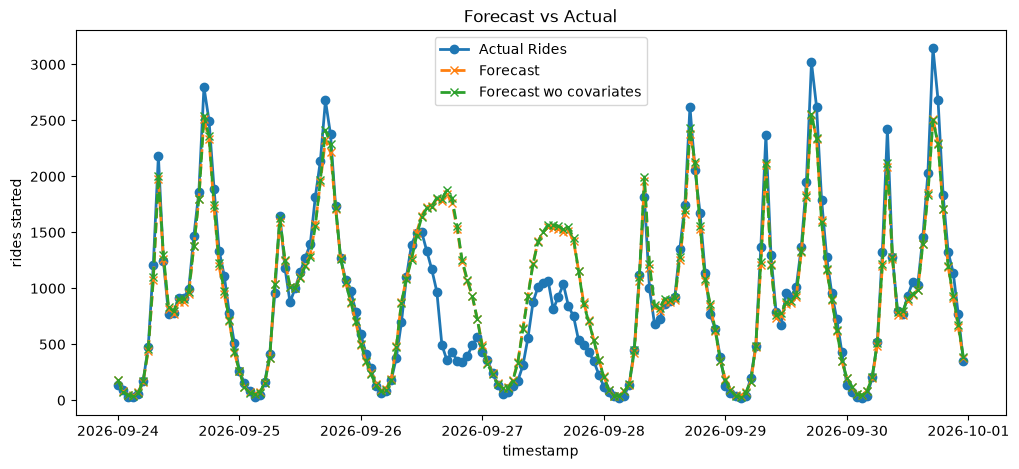

In [10]:
def create_forecast(forecast): 
    # needed so that we can compare the actual values with the forecast.
    fc = np.asarray(forecast[0])
    return fc[0, fc.shape[1] // 2, :] 
    # here I only look at the 50th percentile. # During Phase 2 maybe check different percentiles. ##################################################

preds = create_forecast(forecast)
preds_no_cov = create_forecast(forecast_wo_cov)


actuals = target_values[prediction_window:]
timestamps = hourly["timestamp"].iloc[prediction_window:].values

plt.figure(figsize=(12, 5))
plt.plot(timestamps, actuals, label="Actual Rides", marker="o", linewidth=2)
plt.plot(timestamps, preds,label="Forecast", marker="x",linestyle="--",linewidth=2,)
plt.plot(timestamps, preds_no_cov,label="Forecast wo covariates", marker="x",linestyle="--",linewidth=2,)
plt.title("Forecast vs Actual")
plt.xlabel("timestamp")
plt.ylabel("rides started")
plt.legend()
plt.show()

# here we can see the first failure point on 2026-09-26 - 2026-09-28 whre the model severly overpredicts

In [11]:
# now predict any 1 week in data
weeks_back = 40

target_columns = ["rides_started"]
future_covariate_columns = ["temp","precip","is_holiday",]
past_covariate_columns = ["humidity"]

target_values = hourly["rides_started"].values
past_covariate_values = hourly[past_covariate_columns].fillna(0).values.T
future_covariate_values = hourly[future_covariate_columns].fillna(0).values.T

# predict 1 week of data using full past year of context
context_length = 365 * 24 # 24*365 is a full year
prediction_length = 7*24 # 1 week

prediction_end = len(hourly) - (weeks_back - 1) * prediction_length
prediction_start = prediction_end - prediction_length
context_start = prediction_start - context_length

targets = torch.tensor(target_values[context_start:prediction_start], dtype=torch.float32).unsqueeze(0)# targets have to be (n_targets, context_length)
past_covariates = torch.tensor(past_covariate_values[:, context_start:prediction_start], dtype=torch.float32)
future_covariates = torch.tensor(future_covariate_values[:, context_start:prediction_end], dtype=torch.float32)

print(f"Context length in days: {context_length/24}")
print(f"Prediction length in days: {prediction_length/24}")

Context length in days: 365.0
Prediction length in days: 7.0


In [12]:
ts = TimeseriesType(target=targets, past_covariates=past_covariates, future_covariates=future_covariates)
with torch.no_grad():
    forecast = model.forecast([ts], prediction_length=prediction_length, output_type="numpy")

ts_wo_cov = TimeseriesType(target=targets, past_covariates=None, future_covariates=None)
with torch.no_grad():
    forecast_wo_cov = model.forecast([ts_wo_cov], prediction_length=prediction_length, output_type="numpy")    

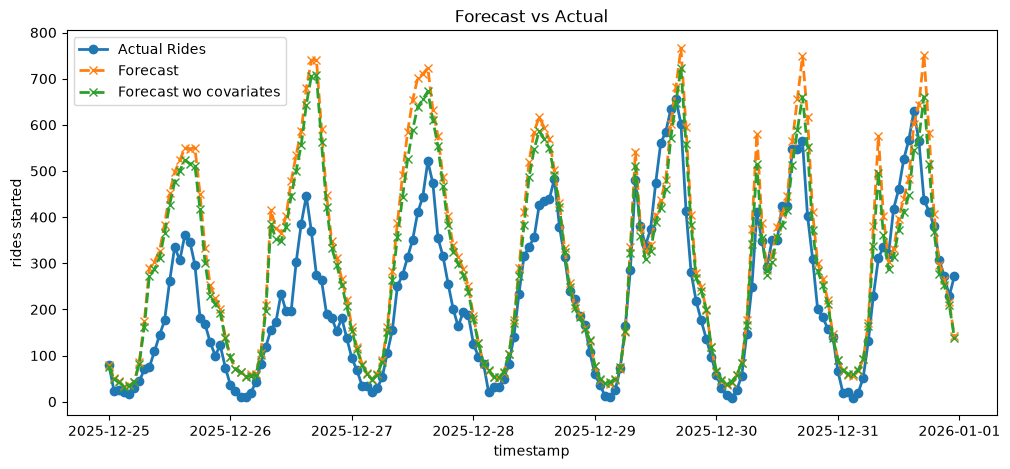

In [13]:
preds = create_forecast(forecast)
preds_no_cov = create_forecast(forecast_wo_cov)
actuals = target_values[prediction_start:prediction_end]
timestamps = hourly["timestamp"].iloc[prediction_start:prediction_end].values

plt.figure(figsize=(12, 5))
plt.plot(timestamps, actuals, label="Actual Rides", marker="o", linewidth=2)
plt.plot(timestamps, preds,label="Forecast", marker="x",linestyle="--",linewidth=2,)
plt.plot(timestamps, preds_no_cov,label="Forecast wo covariates", marker="x",linestyle="--",linewidth=2,)
plt.title("Forecast vs Actual")
plt.xlabel("timestamp")
plt.ylabel("rides started")
plt.legend()
plt.show()



In [14]:
# now  loop over the dataset and make 1 week predictions with the same context: 180days. so predict every week from 2020 to 2026
context_length = 180*24 # 180 days
prediction_length = 7*24 # 1 week

target_columns = ["rides_started"]
future_covariate_columns = ["temp","precip","is_holiday",]
past_covariate_columns = ["humidity"]


target_values = hourly["rides_started"].values
past_covariate_values = hourly[past_covariate_columns].fillna(0).values.T
future_covariate_values = hourly[future_covariate_columns].fillna(0).values.T

all_blocks = []
block_id = 1
prediction_end = len(hourly)


while True:

    prediction_start = prediction_end - prediction_length
    context_start = prediction_start - context_length

    # it should get at least context length as context
    if context_start < 0:
        break

    targets = torch.tensor(target_values[context_start:prediction_start], dtype=torch.float32).unsqueeze(0)# targets have to be (n_targets, context_length)
    past_covariates = torch.tensor(past_covariate_values[:, context_start:prediction_start], dtype=torch.float32)
    future_covariates = torch.tensor(future_covariate_values[:, context_start:prediction_end], dtype=torch.float32)
    

    ts = TimeseriesType(target=targets, past_covariates=past_covariates, future_covariates=future_covariates)

    with torch.no_grad():
        forecast = model.forecast([ts], prediction_length=prediction_length, output_type="numpy")

    preds = create_forecast(forecast)
    actuals = target_values[prediction_start:prediction_end]
    timestamps = hourly["timestamp"].iloc[prediction_start:prediction_end].values

    
    block_df = pd.DataFrame({
        "timestamp": pd.to_datetime(timestamps),
        "block_id": block_id,
        "actual": actuals,
        "forecast": preds,
        "residual": actuals - preds  # Negatives are overpredictions, Positive are underprediction
    })
    all_blocks.append(block_df)

    # shift window back
    prediction_end = prediction_start
    block_id += 1

# Combine weekly predictions
full_eval = pd.concat(all_blocks, ignore_index=True)

weather_columns = [
    "timestamp", "temp", "precip", "humidity", "windspeed", "windgust",
    "is_rain", "is_heavy_rain", "is_snow", "is_holiday", "dow", "bin_of_day"
]


########### for phase 2 using ai maybe create slider that lets user go back over all predictions ####################

In [15]:
#full_eval.to_parquet("tirex2_predictions.parquet", index=False)
#full_eval = pd.read_parquet("tirex2_predictions.parquet")

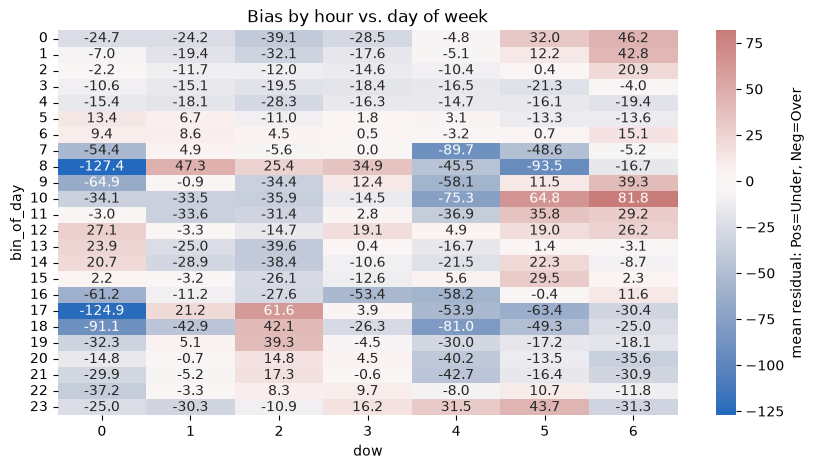

In [16]:
available_cols = [c for c in weather_columns if c in hourly.columns]
full_eval = pd.merge(full_eval, hourly[available_cols], on="timestamp", how="left")

# calculate absolute  error
full_eval["abs_error"] = full_eval["residual"].abs()

# group bias across calendar dimensions
calendar_bias = (full_eval.groupby(["dow", "bin_of_day"]).agg(
        mean_residual=("residual", "mean"),
        mae=("abs_error", "mean"),
        sample_count=("residual", "count"),).reset_index())

# visualize bias across day of week and hour of day
pivot_bias = calendar_bias.pivot(index="bin_of_day", columns="dow", values="mean_residual")

plt.figure(figsize=(10, 5))
sns.heatmap(pivot_bias,cmap="vlag",center=0,annot=True,fmt=".1f",cbar_kws={"label": "mean residual: Pos=Under, Neg=Over"},)
plt.title("Bias by hour vs. day of week")
plt.show()

# clear under prediction during "rush hour" on mondays

In [17]:
# now loop over the dataset and test multiple context lengths to see if the bias still exists
context_lengths_days = [14, 30, 90, 180, 365]  # define the context lengths to test
prediction_length = 7 * 24  # 1 week 

target_columns = ["rides_started"]
future_covariate_columns = ["temp","precip","is_holiday",]
past_covariate_columns = ["humidity"]

target_values = hourly["rides_started"].values
past_covariate_values = hourly[past_covariate_columns].fillna(0).values.T
future_covariate_values = hourly[future_covariate_columns].fillna(0).values.T

all_blocks = []

for ctx_days in context_lengths_days:
    context_length = ctx_days*24
    block_id = 1
    prediction_end = len(hourly)

    while True:
        prediction_start = prediction_end - prediction_length
        context_start = prediction_start - context_length

        if context_start < 0:
            break

        targets = torch.tensor(target_values[context_start:prediction_start], dtype=torch.float32).unsqueeze(0)
        past_covariates = torch.tensor(past_covariate_values[:, context_start:prediction_start],dtype=torch.float32)
        future_covariates = torch.tensor(future_covariate_values[:, context_start:prediction_end],dtype=torch.float32)

        ts = TimeseriesType(target=targets,past_covariates=past_covariates,future_covariates=future_covariates,)

        with torch.no_grad():
            forecast = model.forecast([ts], prediction_length=prediction_length, output_type="numpy")

        preds = create_forecast(forecast)
        actuals = target_values[prediction_start:prediction_end]
        timestamps = hourly["timestamp"].iloc[prediction_start:prediction_end].values

        block_df = pd.DataFrame({
                "timestamp": pd.to_datetime(timestamps),
                "context_length_days": ctx_days,
                "block_id": block_id,
                "actual": actuals,
                "forecast": preds,
                "residual": actuals - preds,  # Negatives are overpredictions, Positives are underpredictions
            })
        all_blocks.append(block_df)

        # shift window back
        prediction_end = prediction_start
        block_id += 1


full_eval = pd.concat(all_blocks, ignore_index=True)

full_eval = pd.merge(full_eval, hourly[available_cols], on="timestamp", how="left")

# calculate absolute  error
full_eval["abs_error"] = full_eval["residual"].abs()

# group bias across calendar dimensions
calendar_bias = (full_eval.groupby(["context_length_days","dow", "bin_of_day"], observed=False).agg(
        mean_residual=("residual", "mean"),
        mae=("abs_error", "mean"),
        sample_count=("residual", "count"),).reset_index())

# mea across different context lengths
print(full_eval.groupby("context_length_days")["abs_error"].mean())

context_length_days
14     104.488824
30     100.783756
90     100.239976
180    101.621325
365    104.659324
Name: abs_error, dtype: float64


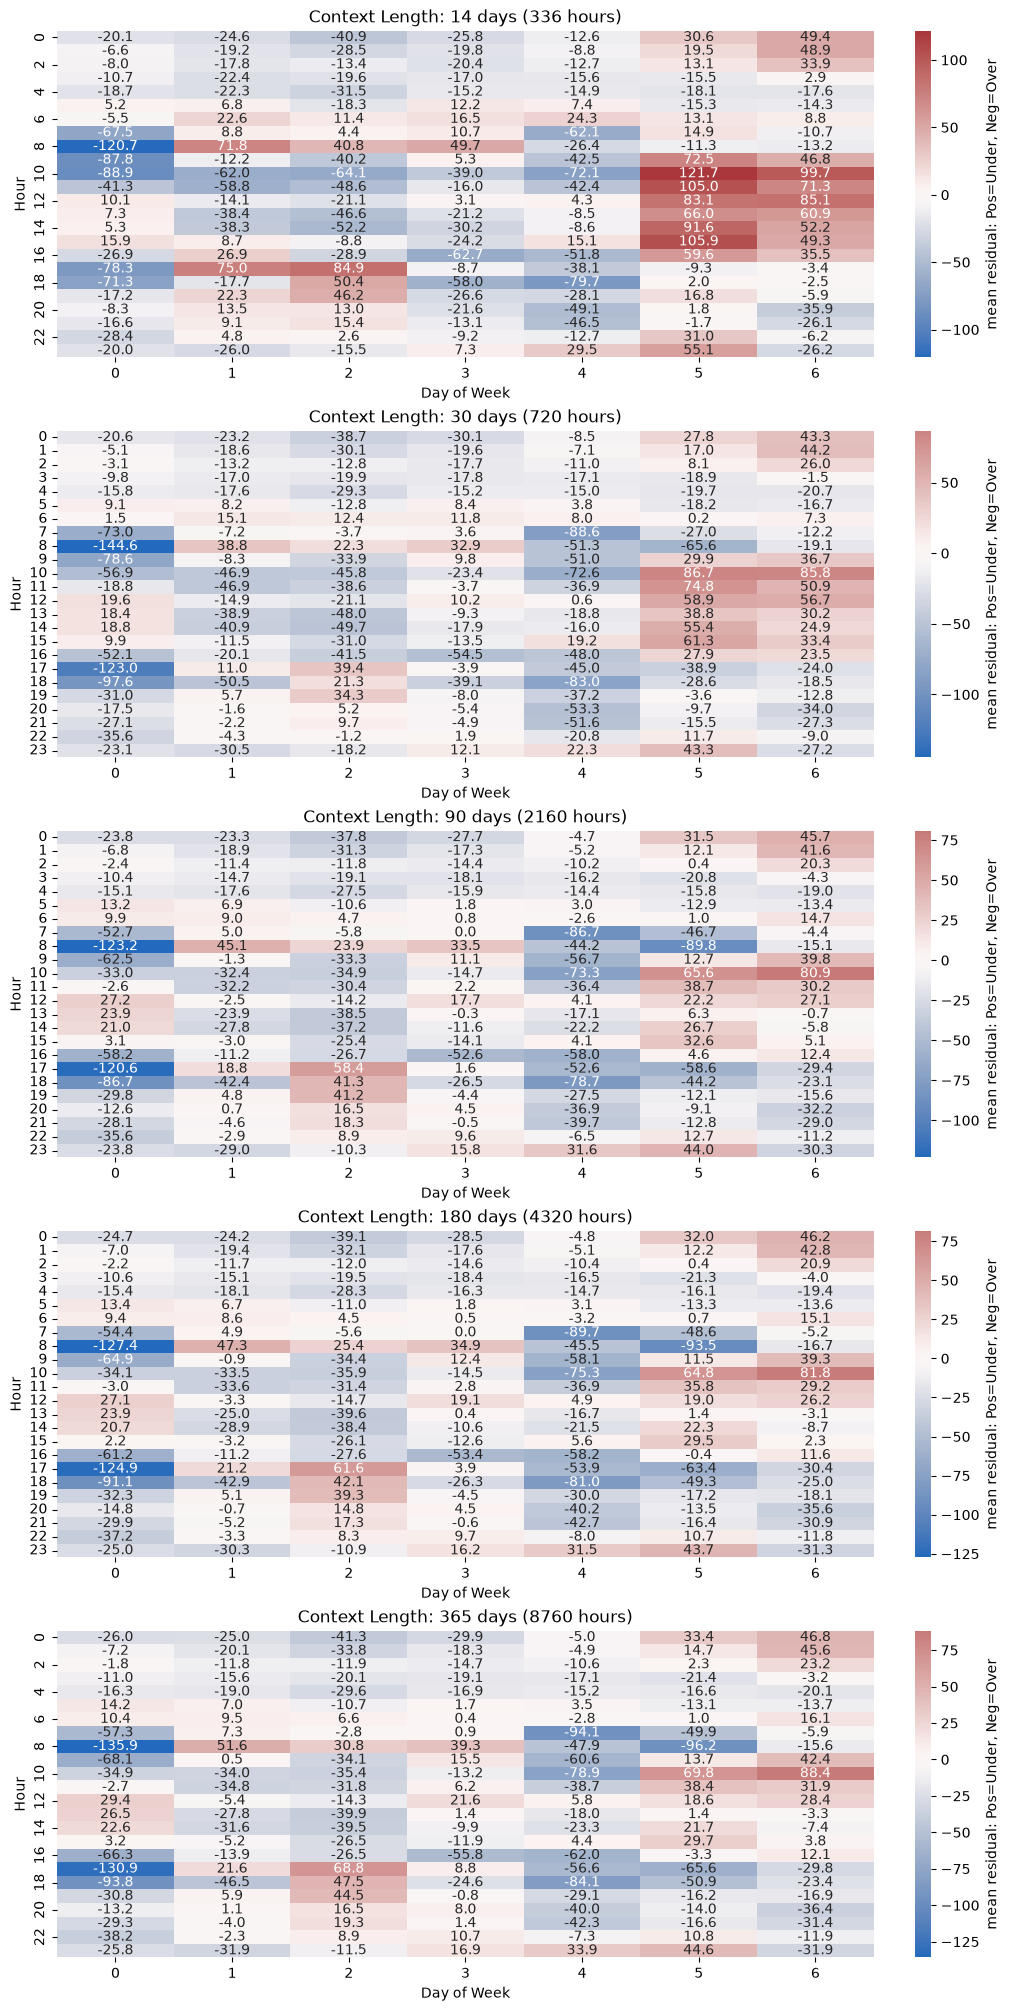

In [18]:
fig, axes = plt.subplots(nrows=len(context_lengths_days), ncols=1, figsize=(10, 4*len(context_lengths_days)),constrained_layout=True)

for ax, ctx_days in zip(axes, context_lengths_days):
    subset = calendar_bias[calendar_bias["context_length_days"] == ctx_days]
    pivot_bias = subset.pivot(index="bin_of_day", columns="dow", values="mean_residual")

    sns.heatmap(pivot_bias,cmap="vlag",center=0,annot=True,fmt=".1f",ax=ax,cbar_kws={"label": "mean residual: Pos=Under, Neg=Over"})

    ax.set_title(f"Context Length: {ctx_days} days ({ctx_days*24} hours)")
    ax.set_ylabel("Hour")
    ax.set_xlabel("Day of Week")

plt.show()

#the underprediction can still be seen here for every context length.

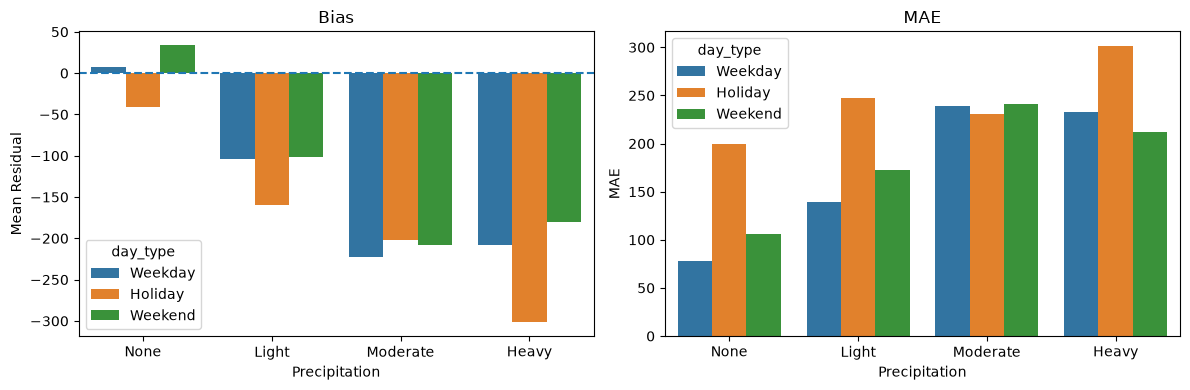

In [19]:
# now test effect of weather (rain) on predictions for different "day types"
full_eval["is_weekend"] = full_eval["dow"].isin([5, 6]).astype(int)

full_eval["precip_bin"] = pd.cut(
    full_eval["precip"],
    bins=[-0.001, 0.0, 1.0, 5.0, np.inf],
    labels=["None", "Light", "Moderate", "Heavy"],
)

weather_check = (full_eval.groupby(["precip_bin", "is_weekend", "is_holiday"], observed=False).agg(
        bias=("residual", "mean"),
        mae=("abs_error", "mean"),
        n_samples=("actual", "count")).reset_index())

#create labels for plot
def label_day(row):
    if row["is_holiday"] == 1:
        return "Holiday"
    if row["is_weekend"] == 1:
        return "Weekend"
    else: 
        return "Weekday"

weather_check["day_type"] = weather_check.apply(label_day, axis=1)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bias
sns.barplot(data=weather_check, x="precip_bin", y="bias", hue="day_type", ax=axes[0])
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Bias")
axes[0].set_xlabel("Precipitation")
axes[0].set_ylabel("Mean Residual")

# MAE
sns.barplot(data=weather_check, x="precip_bin", y="mae", hue="day_type", ax=axes[1])
axes[1].set_title("MAE")
axes[1].set_xlabel("Precipitation")
axes[1].set_ylabel("MAE")

plt.tight_layout()
plt.show()

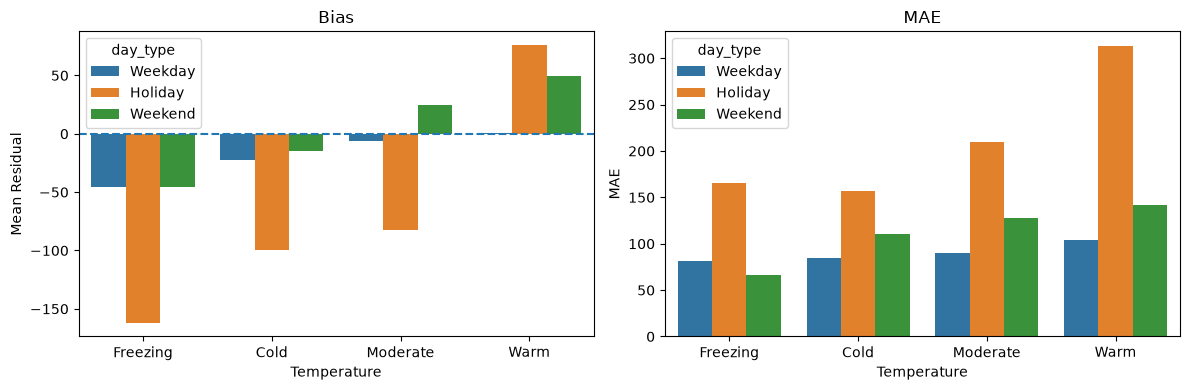

In [20]:
# now test effect of weather (temp) on predictions for different "day types"
full_eval["is_weekend"] = full_eval["dow"].isin([5, 6]).astype(int)

full_eval["temp_bin"] = pd.cut(
    full_eval["temp"],
    bins=[-30, 0.0, 15, 22, np.inf],
    labels=["Freezing", "Cold", "Moderate", "Warm"],
)

weather_check = (full_eval.groupby(["temp_bin", "is_weekend", "is_holiday"], observed=False).agg(
        bias=("residual", "mean"),
        mae=("abs_error", "mean"),
        n_samples=("actual", "count")).reset_index())

weather_check["day_type"] = weather_check.apply(label_day, axis=1)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bias
sns.barplot(data=weather_check, x="temp_bin", y="bias", hue="day_type", ax=axes[0])
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Bias")
axes[0].set_xlabel("Temperature")
axes[0].set_ylabel("Mean Residual")

# MAE
sns.barplot(data=weather_check, x="temp_bin", y="mae", hue="day_type", ax=axes[1])
axes[1].set_title("MAE")
axes[1].set_xlabel("Temperature")
axes[1].set_ylabel("MAE")

plt.tight_layout()
plt.show()
#model seemingly also doesnt use temperature covariate (or at least as much as it should). further analyzis on rain only since the bias is larger.

context_length_days
14     106.212440
30     103.666274
90     102.921485
180    104.330525
365    107.604488
Name: abs_error, dtype: float64


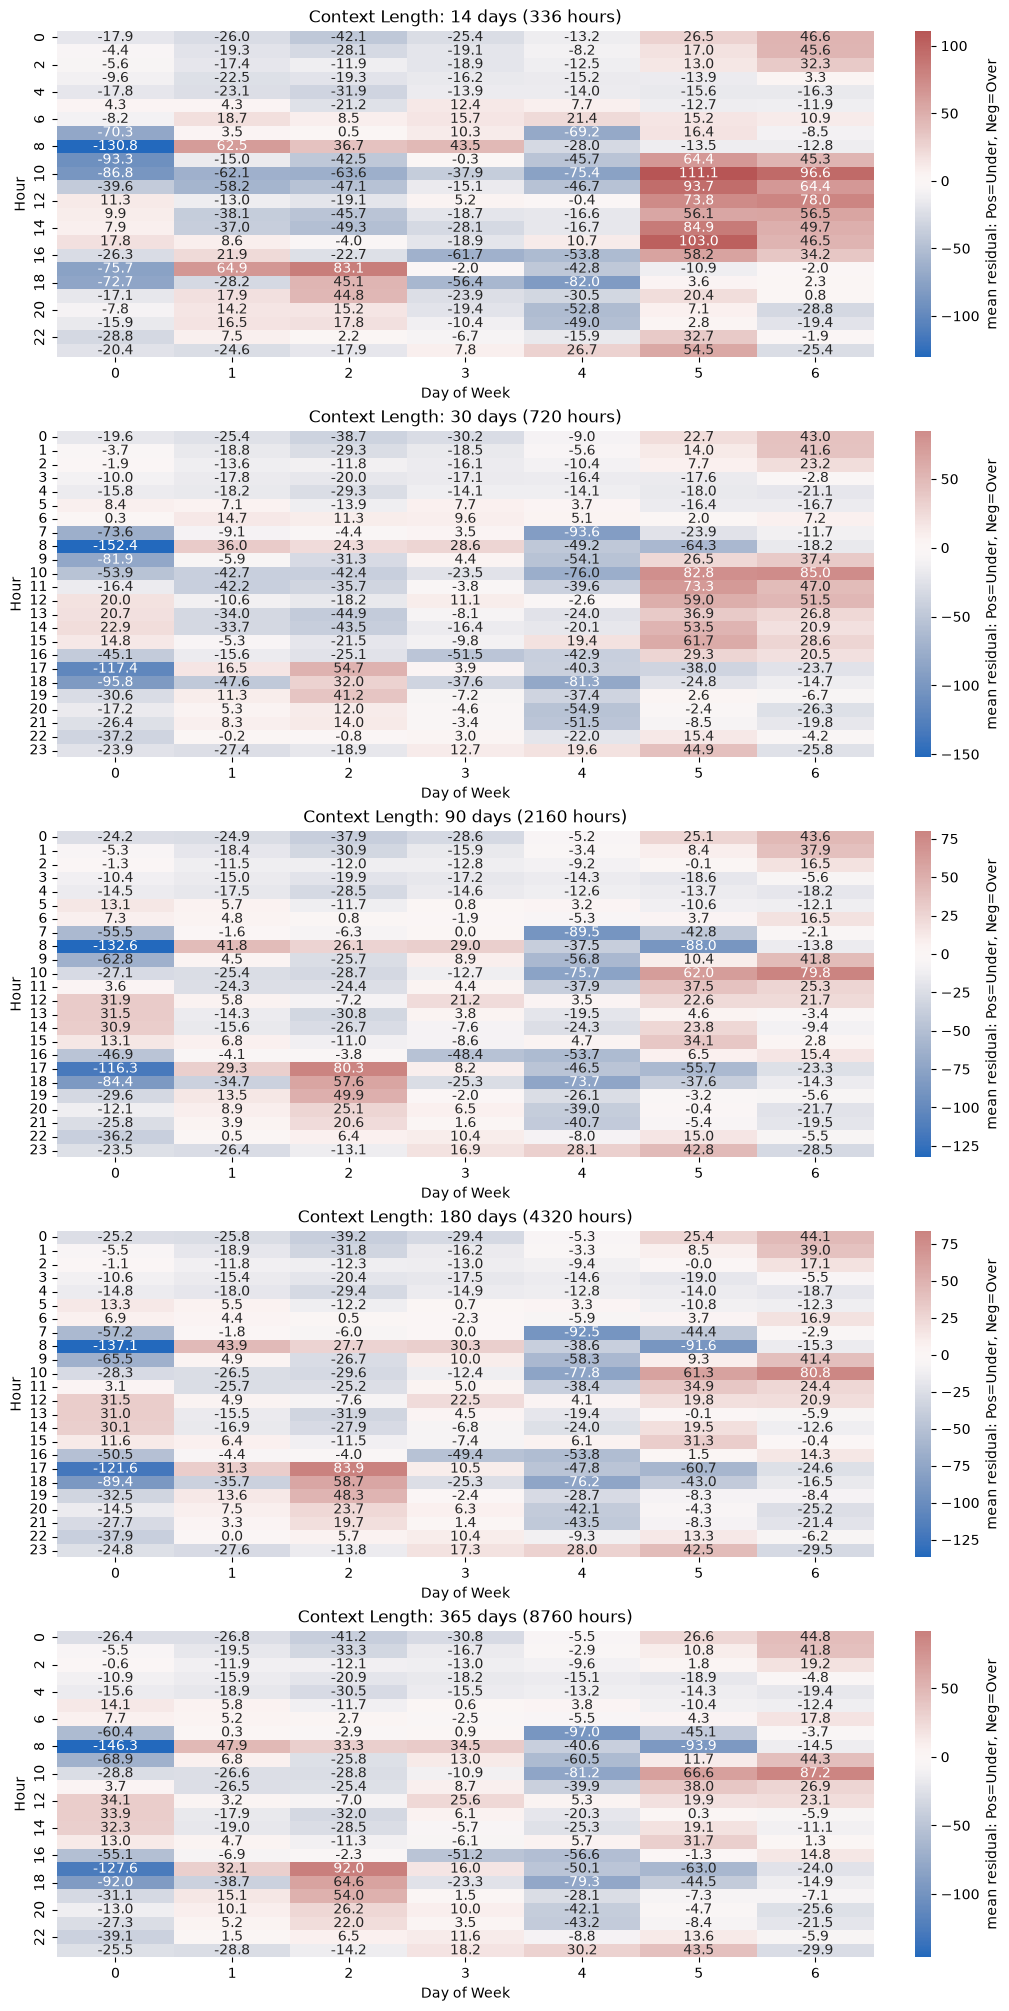

In [21]:
# now test if mondays rush hour underprediction can be removed by adding calender information to the covariates and also information about rider type
# now loop over the dataset and test multiple context lengths to see if the bias still exists
context_lengths_days = [14, 30, 90, 180, 365]  # define the context lengths to test
prediction_length = 7 * 24  # 1 week 

target_columns = ["rides_started"]

future_covariate_columns = [
    "hour", "dow", "is_weekend", "is_holiday", # calender
    "temp", "precip", "humidity", "windspeed"  # weather
]

past_covariate_columns = ["member_rides", "casual_rides", "avg_duration_min"]

target_values = hourly["rides_started"].values
past_covariate_values = hourly[past_covariate_columns].fillna(0).values.T
future_covariate_values = hourly[future_covariate_columns].fillna(0).values.T

all_blocks = []

for ctx_days in context_lengths_days:
    context_length = ctx_days * 24
    block_id = 1
    prediction_end = len(hourly)

    while True:
        prediction_start = prediction_end - prediction_length
        context_start = prediction_start - context_length

        if context_start < 0:
            break

        targets = torch.tensor(target_values[context_start:prediction_start], dtype=torch.float32).unsqueeze(0)
        past_covariates = torch.tensor(past_covariate_values[:, context_start:prediction_start],dtype=torch.float32)
        future_covariates = torch.tensor(future_covariate_values[:, context_start:prediction_end],dtype=torch.float32)

        ts = TimeseriesType(target=targets,past_covariates=past_covariates,future_covariates=future_covariates,)

        with torch.no_grad():
            forecast = model.forecast([ts], prediction_length=prediction_length, output_type="numpy")

        preds = create_forecast(forecast)
        actuals = target_values[prediction_start:prediction_end]
        timestamps = hourly["timestamp"].iloc[prediction_start:prediction_end].values

        block_df = pd.DataFrame({
                "timestamp": pd.to_datetime(timestamps),
                "context_length_days": ctx_days,
                "block_id": block_id,
                "actual": actuals,
                "forecast": preds,
                "residual": actuals - preds,  # Negatives are overpredictions, Positives are underpredictions
            })
        all_blocks.append(block_df)

        # shift window back
        prediction_end = prediction_start
        block_id += 1


full_eval = pd.concat(all_blocks, ignore_index=True)

full_eval = pd.merge(full_eval, hourly[available_cols], on="timestamp", how="left")

# calculate absolute  error
full_eval["abs_error"] = full_eval["residual"].abs()

# group bias across calendar dimensions
calendar_bias = (full_eval.groupby(["context_length_days","dow", "bin_of_day"], observed=False).agg(
        mean_residual=("residual", "mean"),
        mae=("abs_error", "mean"),
        sample_count=("residual", "count"),).reset_index())

# mea across different context lengths
print(full_eval.groupby("context_length_days")["abs_error"].mean())

fig, axes = plt.subplots(nrows=len(context_lengths_days), ncols=1, figsize=(10, 4*len(context_lengths_days)),constrained_layout=True)

for ax, ctx_days in zip(axes, context_lengths_days):
    subset = calendar_bias[calendar_bias["context_length_days"] == ctx_days]
    pivot_bias = subset.pivot(index="bin_of_day", columns="dow", values="mean_residual")

    sns.heatmap(pivot_bias,cmap="vlag",center=0,annot=True,fmt=".1f",ax=ax,cbar_kws={"label": "mean residual: Pos=Under, Neg=Over"})

    ax.set_title(f"Context Length: {ctx_days} days ({ctx_days*24} hours)")
    ax.set_ylabel("Hour")
    ax.set_xlabel("Day of Week")

plt.show()

# the added covariates didnt help, they made the undepredictions worse.

In [22]:
# now i want to try "counterfactuals" where i change the data and look at how the output changes
# When there is rain in a future forecast, does the model reduce the predicted bike rentals downwards?
target_columns = ["rides_started"]
future_covariate_columns = ["temp","precip","is_holiday"]

past_covariate_columns = ["humidity"]

target_values = hourly["rides_started"].values
past_covariate_values = hourly[past_covariate_columns].fillna(0).values.T
future_covariate_values = hourly[future_covariate_columns].fillna(0).values.T

# predict last week of data using 180 days
context_length = 180*24 
prediction_length = 7*24 #1week
precip_idx = future_covariate_columns.index("precip")


cf_records = []
prediction_end = len(hourly)

while True:
    prediction_start = prediction_end - prediction_length
    context_start = prediction_start - context_length
    if context_start < 0:
        break

    targets = torch.tensor(target_values[context_start:prediction_start], dtype=torch.float32).unsqueeze(0)
    past_covariates = torch.tensor(past_covariate_values[:, context_start:prediction_start], dtype=torch.float32)
    future_covariates = torch.tensor(future_covariate_values[:, context_start:prediction_end], dtype=torch.float32)
    
    rain_slice = future_covariates[precip_idx, context_length:].numpy()
    hours_slice = hourly["hour"].iloc[prediction_start:prediction_end].values
    
    # only test windows that actually contain rain
    if rain_slice.max() > 0.1:
        
        # set future rain to 0.0
        future_dry = future_covariates.clone()
        future_dry[precip_idx, context_length:] = 0.0
        
        # no past covariates used
        ts_rain = TimeseriesType(target=targets, past_covariates=None, future_covariates=future_covariates)
        ts_dry  = TimeseriesType(target=targets, past_covariates=None, future_covariates=future_dry)

        # run both
        with torch.no_grad():
            fc = model.forecast([ts_rain, ts_dry], prediction_length=prediction_length, output_type="numpy")
            pred_rain = create_forecast([fc[0]])
            pred_dry  = create_forecast([fc[1]])

        # compare points where it rained
        actuals_slice = target_values[prediction_start:prediction_end]
        rain_mask = rain_slice > 0 # hours where it rains

        model_shifts = pred_rain[rain_mask] - pred_dry[rain_mask] # how the model responds to rain      
        real_drops = actuals_slice[rain_mask] - pred_dry[rain_mask] 

        for h, r, shift, drop in zip(hours_slice[rain_mask],rain_slice[rain_mask], model_shifts, real_drops):
            cf_records.append({"hour": int(h),"precip_mm": r, "model_shift": shift, "actual_drop": drop})

    prediction_end = prediction_start

cf_df = pd.DataFrame(cf_records)

print(f"average model shift from rain: {cf_df['model_shift'].mean()} rides")
print(f"average actual drop during rain: {cf_df['actual_drop'].mean()} rides")

average model shift from rain: -0.18489505350589752 rides
average actual drop during rain: -134.8123641444341 rides


In [23]:
cf_df

,hour,precip_mm,model_shift,actual_drop
0,12,0.1,3.733276,-137.958252
1,15,0.2,-2.461304,-818.030273
2,16,1.3,-3.847534,-1274.608154
3,17,1.7,-4.937378,-1460.194336
4,18,1.6,-4.762573,-1299.817383
...,...,...,...,...
8274,21,1.4,-0.115784,-29.313965
8275,22,0.1,-0.146530,-44.957809
8276,10,0.1,-1.144440,-23.559082
8277,11,0.1,-0.632935,-45.777405


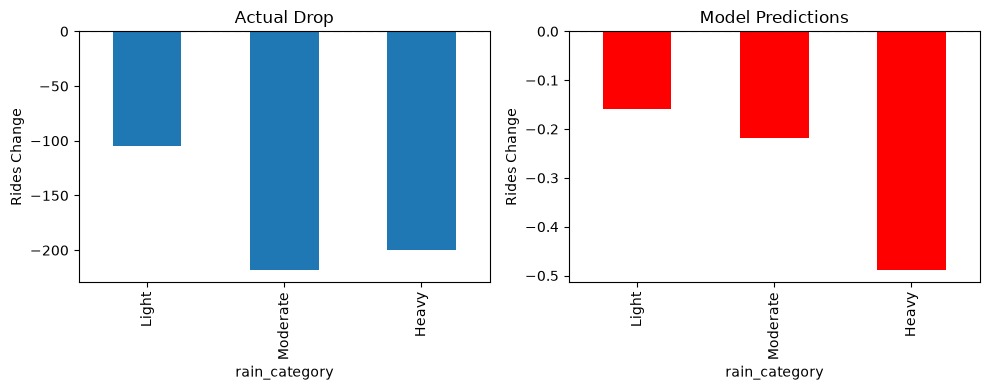

In [24]:
cf_df["rain_category"] = pd.cut(
    cf_df["precip_mm"],
    bins=[0.0, 1.0, 5.0, np.inf],
    labels=[ "Light", "Moderate", "Heavy"],
)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# actual drop
cf_df.groupby("rain_category", observed=False)["actual_drop"].mean().plot.bar(ax=ax1)
ax1.set_title("Actual Drop")
ax1.set_ylabel("Rides Change")
ax1.axhline(0, linestyle="--")

# model drop
cf_df.groupby("rain_category", observed=False)["model_shift"].mean().plot.bar(ax=ax2, color="red")
ax2.set_title("Model Predictions")
ax2.set_ylabel("Rides Change")
ax2.axhline(0, linestyle="--")

plt.tight_layout()
plt.show()


# it seems like the model doesn't use the covariates at all since there is no real drop when it rains

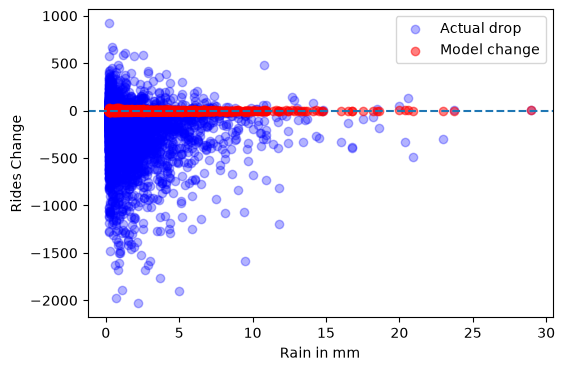

In [25]:
rain_df = cf_df[cf_df["precip_mm"] > 0.1]
plt.figure(figsize=(6, 4))
plt.scatter(rain_df["precip_mm"], rain_df["actual_drop"], color="blue", alpha=0.3, label="Actual drop")
plt.scatter(rain_df["precip_mm"], rain_df["model_shift"], color="red", alpha=0.5, label="Model change")
plt.axhline(0, linestyle="--")
plt.xlabel("Rain in mm")
plt.ylabel("Rides Change")
plt.legend()
plt.show()

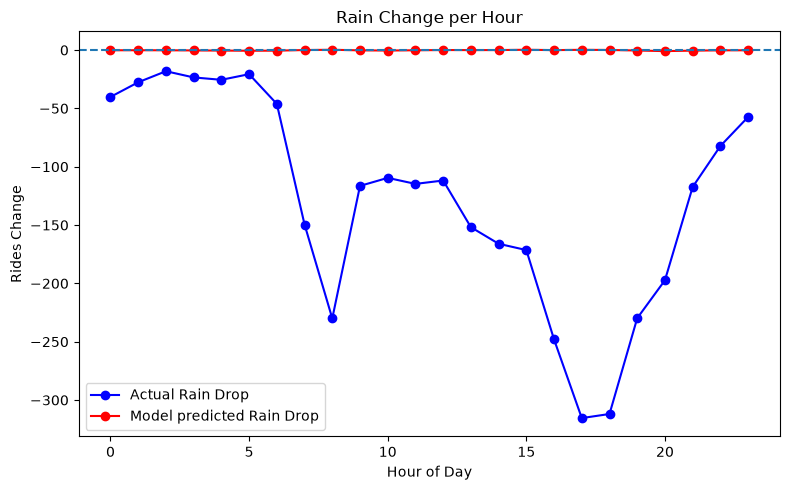

In [26]:
# plot the predicted rain drop per hour vs the actual drop of rides when it rains
fig, ax = plt.subplots(figsize=(8, 5))

hourly_agg = cf_df.groupby("hour")[["actual_drop", "model_shift"]].mean()
hourly_agg.plot(ax=ax, color=["blue", "red"], marker="o")

ax.set_title("Rain Change per Hour")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Rides Change")
ax.axhline(0, linestyle="--")
ax.legend(["Actual Rain Drop", "Model predicted Rain Drop"])

plt.tight_layout()
plt.show()

#confirms that tirex 2 doesnt use the precipitation covariate at all

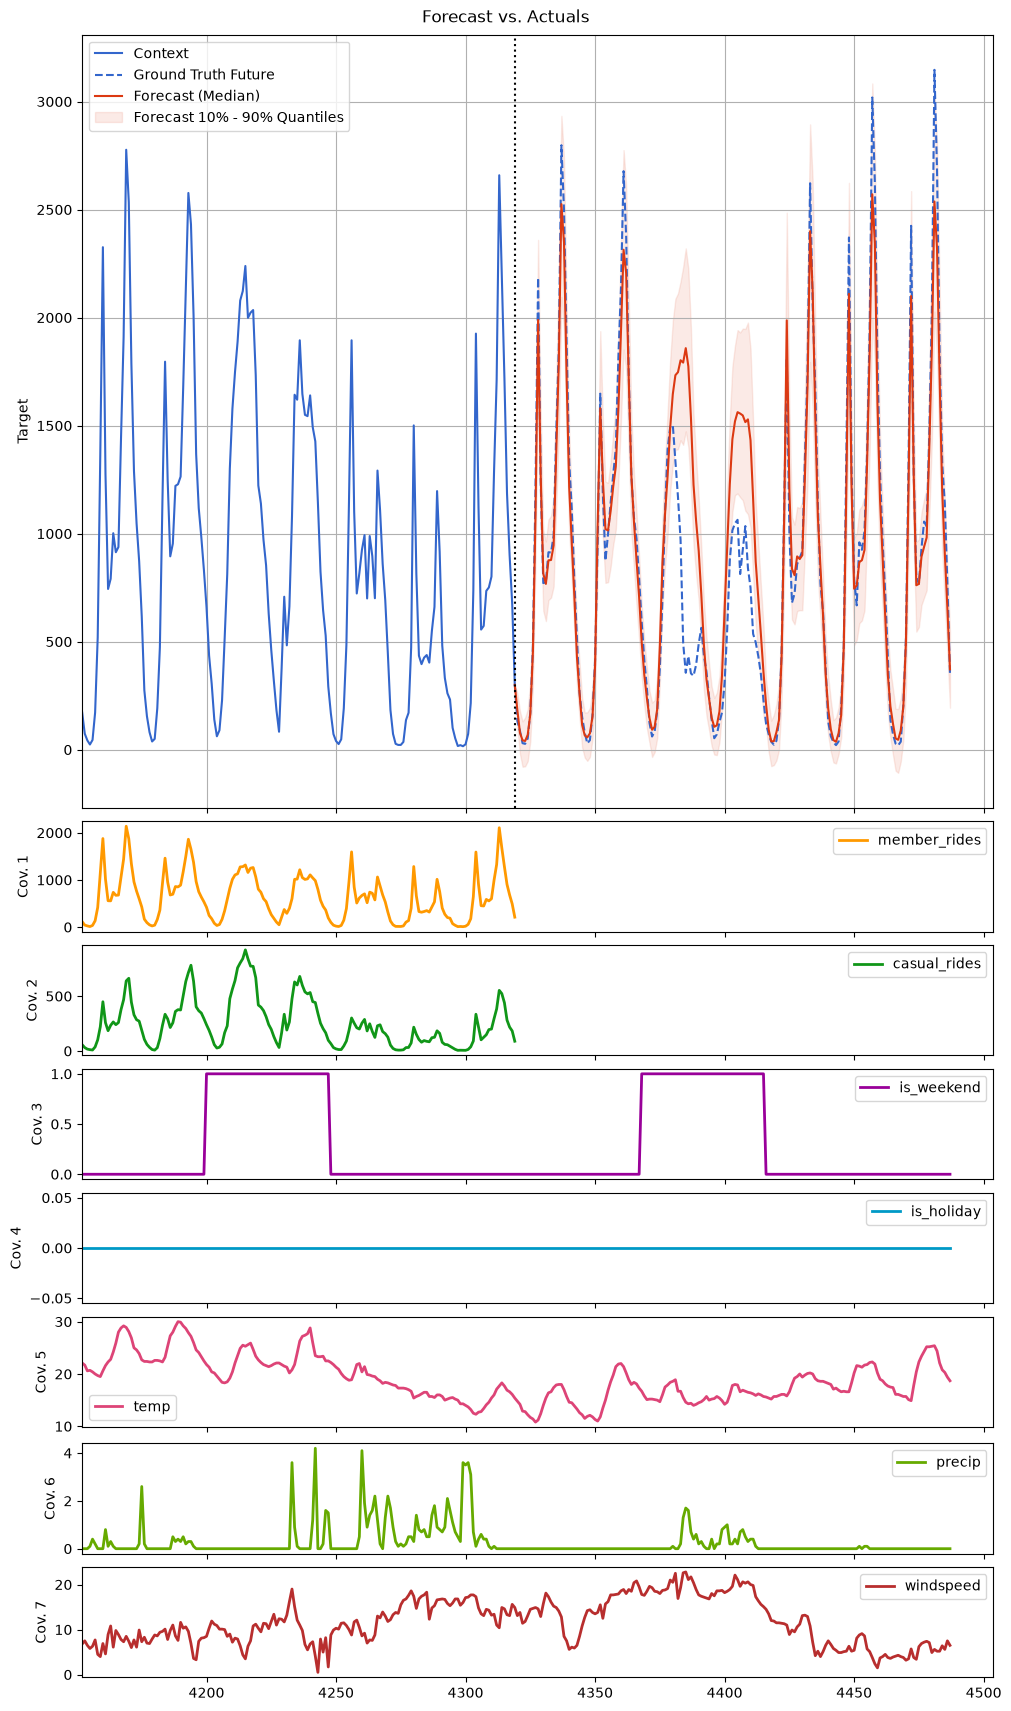

In [27]:
# now use tirex 2 plotting function to show covariates

target_columns = ["rides_started"]
future_covariate_columns = [
    "is_weekend", "is_holiday",
    "temp", "precip", "windspeed",
]
past_covariate_columns = ["member_rides", "casual_rides"]

target_values = hourly["rides_started"].values
past_covariate_values = hourly[past_covariate_columns].fillna(0).values.T
future_covariate_values = hourly[future_covariate_columns].fillna(0).values.T

# predict last week of data using 180 days of context
context_length = 24 * 180 # 180 days
prediction_length = 7 * 24 # 1 week
prediction_window = len(hourly) - prediction_length
context_start = prediction_window - context_length

targets = torch.tensor(target_values[context_start:prediction_window], dtype=torch.float32).unsqueeze(0)
past_covariates = torch.tensor(past_covariate_values[:, context_start:prediction_window], dtype=torch.float32)
future_covariates = torch.tensor(future_covariate_values[:, context_start:], dtype=torch.float32)

ts = TimeseriesType(target=targets, past_covariates=past_covariates, future_covariates=future_covariates)

with torch.no_grad():
    forecast = model.forecast([ts], prediction_length=prediction_length)

actuals = target_values[prediction_window:]

plot_params = dict(
    input=ts,
    forecast=forecast[0],
    target_index=0,
    ground_truth=actuals,
    past_cov_labels=past_covariate_columns,
    future_cov_labels=future_covariate_columns,
    quantiles=(0.1, 0.9),
    max_context_to_show=24*7,
    title="Forecast vs. Actuals"
)

_ = plot_multivariate(**plot_params, engine="matplotlib")

In [28]:
# the last thing that i want to test is when the predictions start on a different day of the week
# Now the prediction window is shifted back by 1 day instead of 1 week 
context_length = 180 * 24  # 180 days
prediction_length = 7 * 24   # 1 week

target_columns = ["rides_started"]
future_covariate_columns = ["temp", "precip", "is_holiday"]
past_covariate_columns = ["humidity"]

target_values = hourly["rides_started"].values
past_covariate_values = hourly[past_covariate_columns].fillna(0).values.T
future_covariate_values = hourly[future_covariate_columns].fillna(0).values.T

all_blocks = []
block_id = 1
prediction_end = len(hourly)
step_size = 24  # windows is shifted by 1 day

while True:
    prediction_start = prediction_end - prediction_length
    context_start = prediction_start - context_length

    if context_start < 0:
        break

    targets = torch.tensor(target_values[context_start:prediction_start], dtype=torch.float32).unsqueeze(0)
    past_covariates = torch.tensor(past_covariate_values[:, context_start:prediction_start], dtype=torch.float32)
    future_covariates = torch.tensor(future_covariate_values[:, context_start:prediction_end], dtype=torch.float32)

    ts = TimeseriesType(target=targets, past_covariates=past_covariates, future_covariates=future_covariates)

    with torch.no_grad():
        forecast = model.forecast([ts], prediction_length=prediction_length, output_type="numpy")

    preds = create_forecast(forecast)
    actuals = target_values[prediction_start:prediction_end]
    timestamps = hourly["timestamp"].iloc[prediction_start:prediction_end].values

    # save start day of each week
    start_dow = pd.Timestamp(timestamps[0]).dayofweek

    block_df = pd.DataFrame({
        "timestamp": pd.to_datetime(timestamps),
        "block_id": block_id,
        "start_dow": start_dow,
        "forecast_horizon_hours": np.arange(len(timestamps)),
        "actual": actuals,
        "forecast": preds,
        "residual": actuals - preds,  # Negatives are overpredictions, Positives are underpredictions
    })
    all_blocks.append(block_df)

    prediction_end = prediction_end - step_size
    block_id += 1


full_eval = pd.concat(all_blocks, ignore_index=True)
full_eval = pd.merge(full_eval, hourly[available_cols], on="timestamp", how="left")
full_eval["abs_error"] = full_eval["residual"].abs()


# group bias across calendar dimensions
calendar_bias = (full_eval.groupby(["dow", "bin_of_day"]).agg(
        mean_residual=("residual", "mean"),
        mae=("abs_error", "mean"),
        sample_count=("residual", "count"),).reset_index())


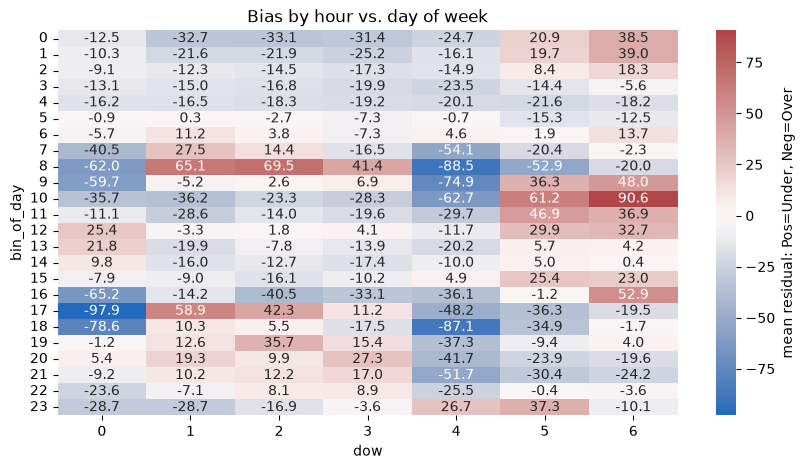

In [29]:
pivot_bias = calendar_bias.pivot(index="bin_of_day", columns="dow", values="mean_residual")

plt.figure(figsize=(10, 5))
sns.heatmap(pivot_bias,cmap="vlag",center=0,annot=True,fmt=".1f",cbar_kws={"label": "mean residual: Pos=Under, Neg=Over"},)
plt.title("Bias by hour vs. day of week")
plt.show()

# still underpredicts monday rush hours. but less than when starting on thursday 

In [31]:
# check if there is enough rain in the dataset that the model could use 
total_hours = len(hourly)
rain_hours = (hourly["precip"] > 0.0).sum()
heavy_rain_hours = (hourly["precip"] > 1.0).sum()

print(f"Total hours: {total_hours}")
print(f"Hours with rain {rain_hours}, {(rain_hours/total_hours)*100}%")
print(f"Hours with moderate/heavy rain: {heavy_rain_hours}, {(heavy_rain_hours/total_hours)*100}%")

# How much rain in 180 days context window

context_length = 180*24 # 180 days
prediction_length = 7*24 # 1 week
prediction_end = len(hourly)
step_size = 24

rain_hours_per_context = []

while True:
    prediction_start = prediction_end - prediction_length
    context_start = prediction_start - context_length

    if context_start < 0:
        break

    context_precip = hourly["precip"].iloc[context_start:prediction_start]
    rain_in_ctx = (context_precip > 0.0).sum()
    rain_hours_per_context.append(rain_in_ctx)

    prediction_end = prediction_end - step_size

avg_rain_in_context = np.mean(rain_hours_per_context)
print(f"Average rain hours across all 180 day context windows: {avg_rain_in_context} hours (Total hours: {context_length})")
print(f"Percentage of rainy hours: {(avg_rain_in_context / context_length) * 100}%")

Total hours: 59160
Hours with rain 9097, 15.376943881000676%
Hours with moderate/heavy rain: 2415, 4.082150101419878%
Average rain hours across all 180 day context windows: 646.8582711715665 hours (Total hours: 4320)
Percentage of rainy hours: 14.97357109193441%
